<a href="https://colab.research.google.com/github/MuhammadAryatamaM/Machine-Learning/blob/main/T4_244107020028_Muhammad_Aryatama_M.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.simplefilter('ignore')
import seaborn as sns
from scipy.stats import mode
from sklearn import metrics
from sklearn.cluster import DBSCAN
from sklearn.cluster import KMeans
from sklearn.cluster import MiniBatchKMeans
from sklearn.cluster import SpectralClustering
from sklearn.datasets import make_blobs
from sklearn.datasets import make_moons
from sklearn.datasets import load_digits
from sklearn.datasets import load_sample_image
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import pairwise_distances_argmin
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Seleksi Fitur

X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


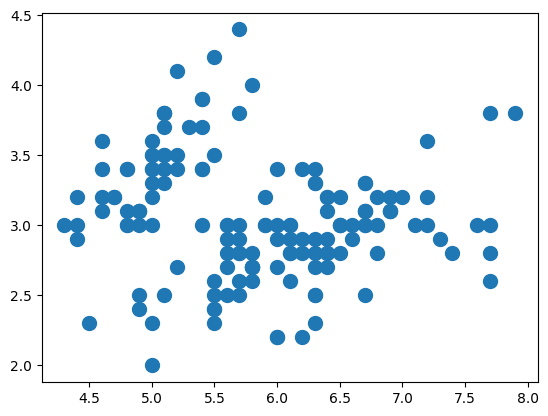

In [ ]:
# Plot Data
# Karena data 4 dimensi, maka plot cluster berdasarkan Sepal Length & Sepal Width aja

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

# Praktikum 1 - KMeans

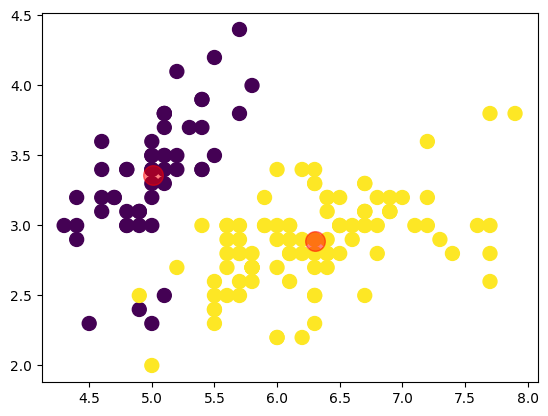

In [ ]:
# inisialisasi model KMeans dengan 2 cluster
cl_kmeans = KMeans(n_clusters=2)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

# Plot hasil cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# mengambil nilai centroid tiap cluster
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

## Cek Nilai Sum of Squared Errors (SSE)

In [ ]:
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


## Implementasi Metode Elbow

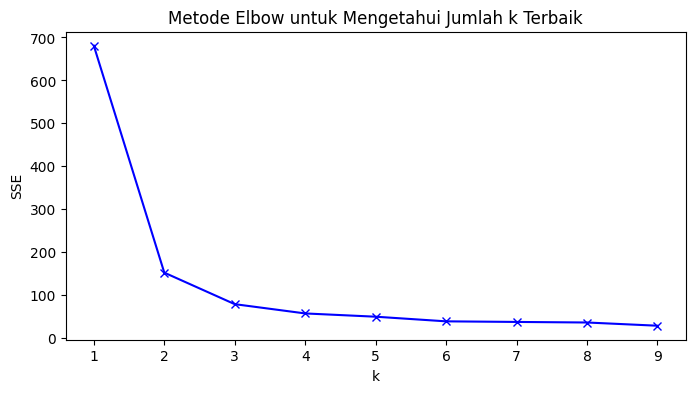

In [ ]:
# List nilai SSE/jumlah kuadrat jarak
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
  kmeanModel = KMeans(n_clusters=k)

  # melatih model data X, mencari pusat cluster
  kmeanModel.fit(X)

  # inertia_ memberi tau seberapa padat cluster. makin kecil nilai makin rapat
  sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

Nilai SSE selalu menurun seiring dengan bertambahnya jumlah k karena kalau ada lebih banyak cluster, setiap titik data akan punya "rumah" yang lebih dekat.

Mencari "Siku" (Elbow): Cari titik di mana penurunan SSE mulai melambat secara signifikan. Setelah titik itu, nambahin cluster lagi nggak akan banyak ngurangin SSE.

Kesimpulan Grafik: Penurunan SSE paling drastis terjadi dari k=1 ke k=2, dan dari k=2 ke k=3. Setelah k=3, penurunan SSE mulai melambat. Jadi, jumlah cluster yang paling optimal adalah 3. Di titik ini, kita mendapatkan keseimbangan yang baik antara jumlah cluster dan kerapatan cluster.

In [ ]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94506582597728
k=4; SSE=57.34540931571815
k=5; SSE=49.74079031410785
k=6; SSE=38.93873974358975
k=7; SSE=37.56018787878788
k=8; SSE=36.2429922177238
k=9; SSE=28.739697702659686


# Praktikum 2 - Pengantar KMeans

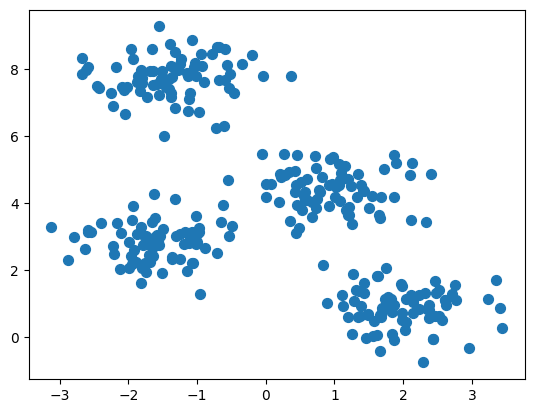

In [ ]:
# membuat 300 data dengan 4 klaster
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

# visualisasi
plt.scatter(X[:, 0], X[:, 1], s=50);

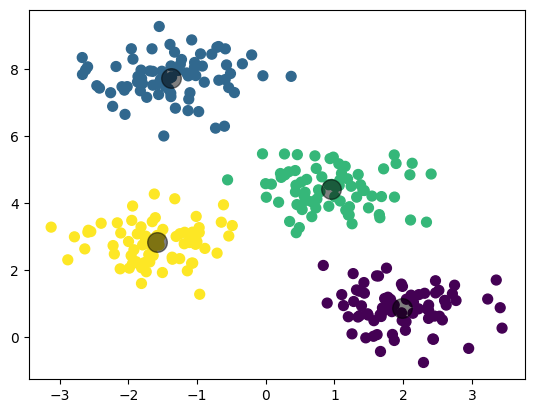

In [ ]:
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)

# memprediksi tiap data di titik data di X ke cluster terdekat, simpan di y_kmeans
y_kmeans = kmeans.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

## Algoritma Expectation-Maximization

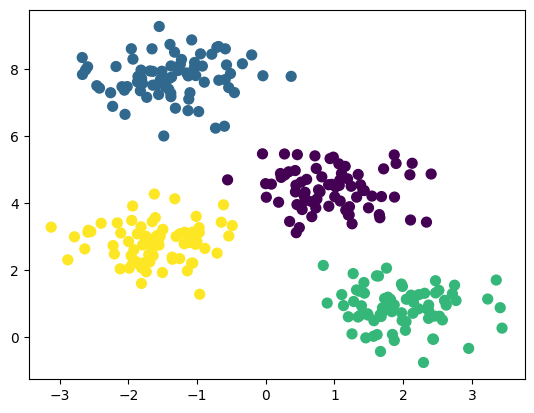

In [ ]:
def find_clusters(X, n_clusters, rseed=2): # implementasi manual KMeans
    # pilih data acak dari X acak untuk jadi pusat/centroid awal
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]

    while True: # loop sampai cluster konvergen/tidak berubah lagi
        # tiap titik data X dimasukkan ke cluster terdekat (label)
        labels = pairwise_distances_argmin(X, centers)

        # update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0) for i in range(n_clusters)])

        # cek konvergensi. jika pusat baru itu sama dengan lama, berhenti
        if np.all(centers == new_centers):
            break
        centers = new_centers

    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

## Perubahan random

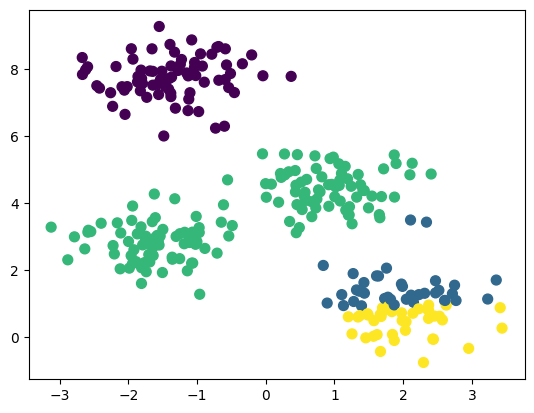

In [ ]:
centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

## Optimalisasi Jumlah Cluster

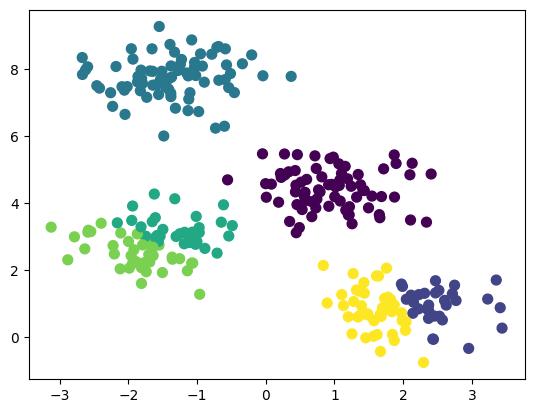

In [ ]:
# Seharusnya pakai Elbow, di sini paksa 6 cluster
labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

## Batas Cluster yang Tidak Selalu Linier

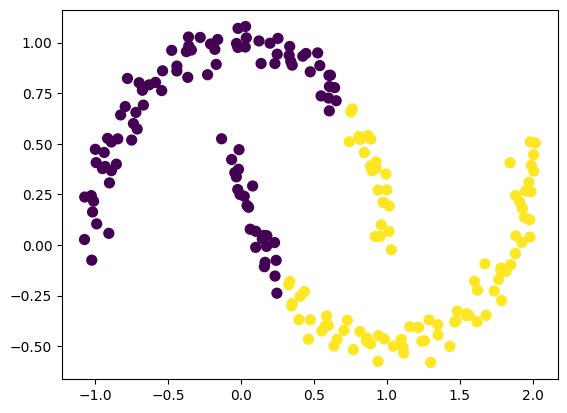

In [ ]:
# ini batas yang dipotong linear, membuat bagian bawah dan atas bisa beda cluster
X, y = make_moons(200, noise=.05, random_state=0)

labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis')

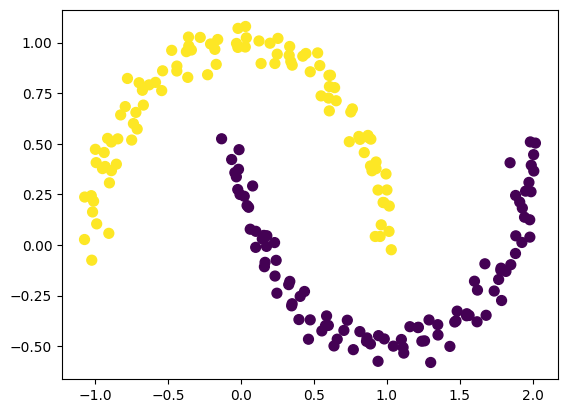

In [ ]:
# dengan SpectralClustering, batasnya tidak linear/bisa melengkung, membuat atas bawah cluster sendiri
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', assign_labels='kmeans')
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

## Contoh Kasus 1: Karakter Angka

In [ ]:
digits = load_digits() # dataset bentuk 10 angka (0-9) 8x8 pixel (64 fitur/dimensi)
digits.data.shape

(1797, 64)

In [ ]:
# terapkan K-Means
kmeans = KMeans(n_clusters=10, random_state=0) # membagi ke 10 cluster berdasarkan 64 fitur
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

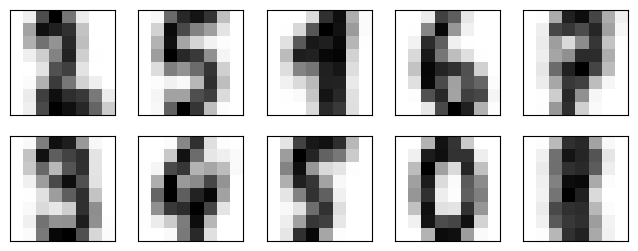

In [ ]:
# melihat gambaran "pola rata-rata" angka yang dipelajari K-Means pada masing-masing cluster
fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8) # dari (10, 64), untuk visualisasi plt
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

In [ ]:
# KMeans hanya memberi nama kelompok berupa angka indeks acak: Kluster 0, Kluster 1, ..., Kluster 9
labels = np.zeros_like(clusters)

# Perulangan memeriksa satu per satu isi dari setiap kluster
# "Di dalam Kluster 0, mayoritas data aslinya angka berapa?"
# Ternyata 90% data di Kluster 0 adalah angka 4. Maka, sistem menetapkan: Kluster 0 = Angka 4.
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

# KMeans berhasil mengelompokkan 74.4% dari 1797 gambar angka tulisan tangan ke kategori angka yang benar
accuracy_score(digits.target, labels)

0.7440178074568725

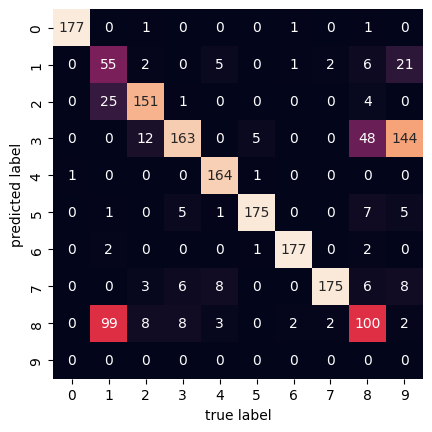

In [ ]:
# menganalisis angka mana saja yang sering salah dikelompokkan KMeans
mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

# Diagonal Utama (Prediksi yang Benar)
# Angka 0: 177 data berhasil dikelompokkan dengan benar (sangat sempurna)
# Angka 2, 3, 5, 9 cukup baik dikelompokkan (148, 154, 136, dan 139 data benar)

# Angka yang Buat K-Means Bingung (Kesalahan Utama)
# Angka 1 Sering Masuk ke Kluster 8 (99)
# 99 gambar angka 1 justru dimasukkan KMeans ke dalam kluster 8, 55 gambar angka 1 masuk ke kluster 1

In [ ]:
# mereduksi data dari 64 dimensi jadi 2 dimensi (n_components=2) sambil mempertahankan jarak lokal antar-sampel
tsne = TSNE(n_components=2, init='random', random_state=0)
digits_proj = tsne.fit_transform(digits.data) # menjalankan kembali KMeans di data hasil proyeksi tadi

# hitung klaster
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits_proj)

# permutasi label
labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

# hitung akurasi
accuracy_score(digits.target, labels)

0.9410127991096272

## Studi Kasus 2: Kompresi Citra

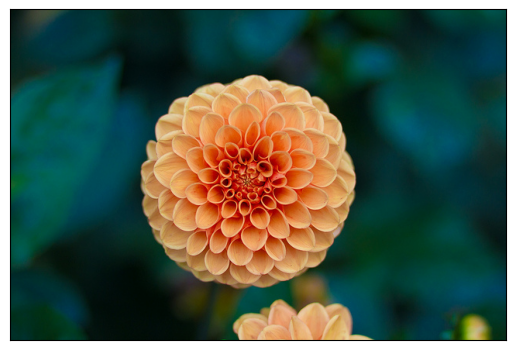

In [ ]:
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower);

In [ ]:
flower.shape

(427, 640, 3)

In [ ]:
data = flower / 255.0
data = data.reshape(427 * 640, 3)
data.shape

(273280, 3)

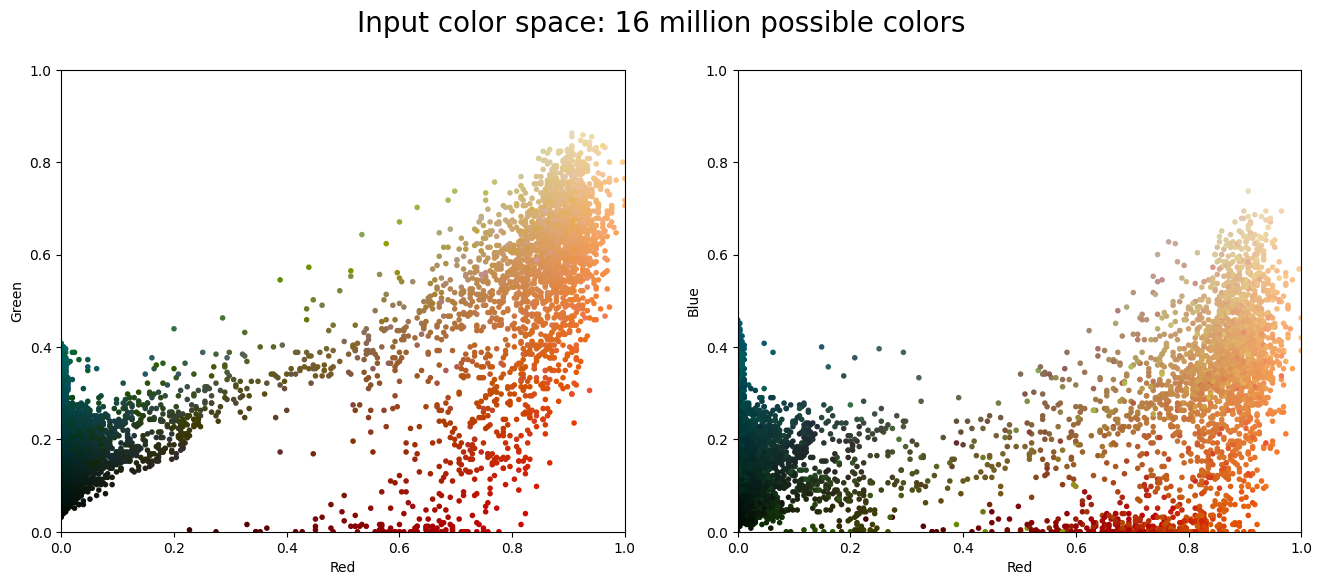

In [ ]:
# mengambil sampel acak 10.000 pixel (N=10000) lalu plot distribusinya ke scatter 2D
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

plot_pixels(data, title='Input color space: 16 million possible colors')

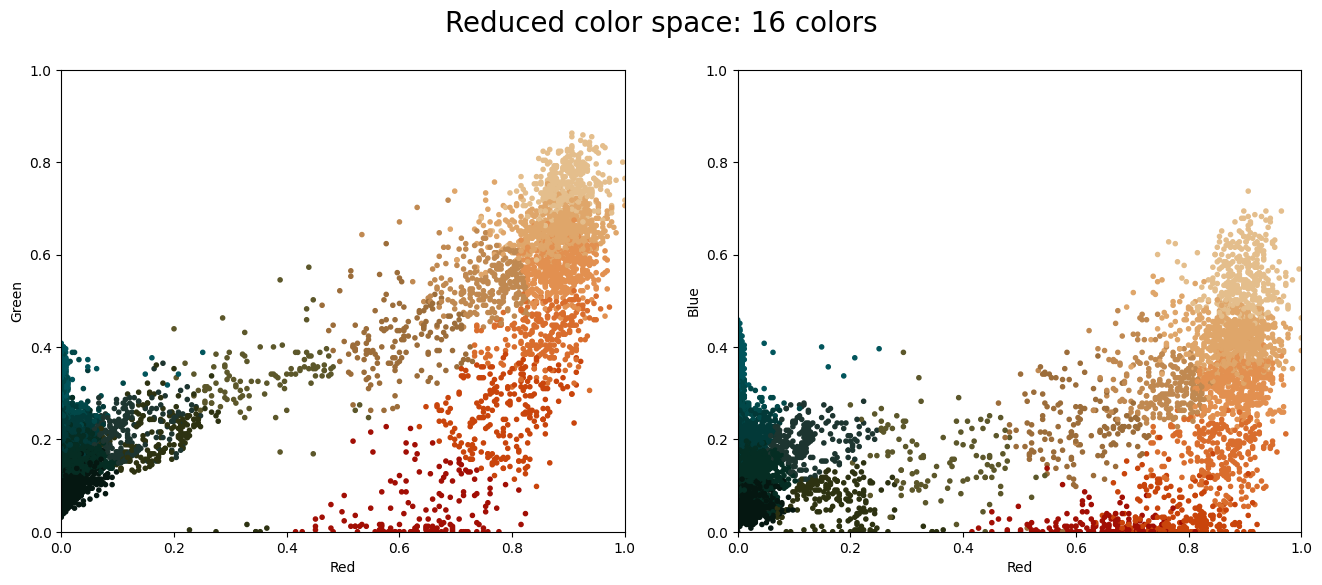

In [ ]:
# variasi KMeans yang lebih cepat (proses pelatihan dilakukan per kelompok kecil/batch)
kmeans = MiniBatchKMeans(16) # mengelompokkan 273280 pixel menjadi 16 kluster warna yang paling mewakili (centroid)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)] # pixel asli diganti dengan nilai warna pusat kluster terdekat

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

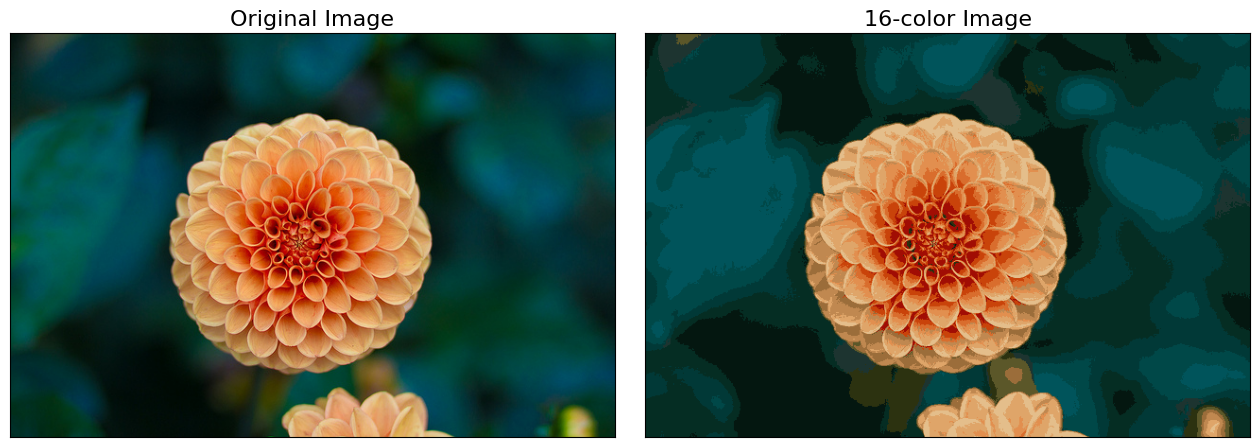

In [ ]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

# Praktikum 3 - Pembuatan Dataset Sintetis

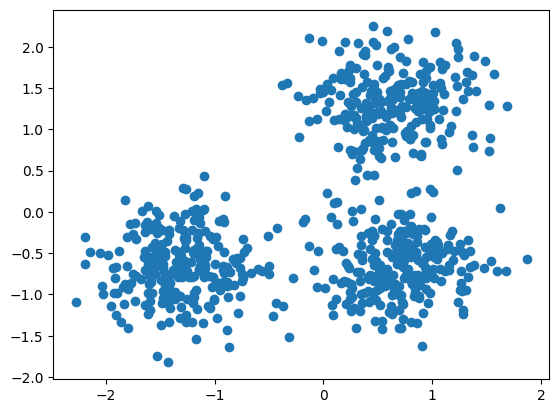

In [ ]:
centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(n_samples=750, centers=centers, cluster_std=0.4, random_state=0)

X = StandardScaler().fit_transform(X)

plt.scatter(X[:, 0], X[:, 1])
plt.show()

## Compute DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

In [ ]:
# epsilson: jarak radius maksimum antar dua titik untuk dianggap sebagai tetangga (neighbors)
# min_samples: jumlah minimum titik tetangga yang harus ada dalam radius eps agar suatu titik dianggap sebagai Core Point
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_ # Hasil pengelompokan titik. Angka 0, 1, 2, ... mewakili ID kluster. Angka -1 mewakili data Noise/Outlier

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


## Evaluasi Kualitas Klasterisasi

In [ ]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


## Visualisasi

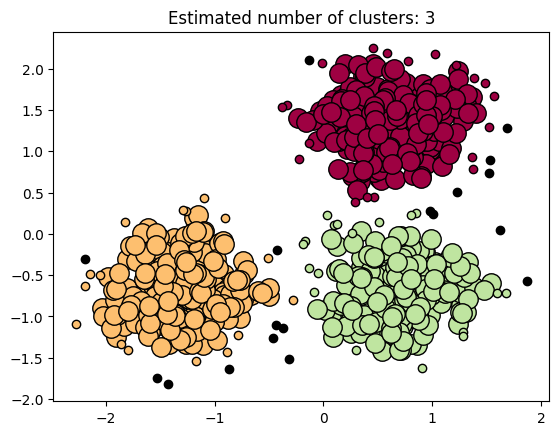

In [ ]:
core_samples_mask = np.zeros_like(db.labels_, dtype=bool) # identifikasi Core Samples
core_samples_mask[db.core_sample_indices_] = True

unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        # warna hitam untuk noise
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    # Plot core samples
    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14, # titik besar berwarna: core samples dalam klaster
    )

    # Plot non-core samples (borders or noise)
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6, # titik kecil berwarna: non-core samples, tetap termasuk klaster.
    )

plt.title("Estimated number of clusters: %d" % n_clusters_)
plt.show()

# Tugas Praktikum

## Tugas KMeans

1. Gunakan data 'Mall_Customers.csv'
2. Tentukan fitur apa yang tepat untuk melakukan clustering (minimal 2)
3. Buatlah model K-Means dengan mempertimbangkan jumlah k yang terbaik.

In [ ]:
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


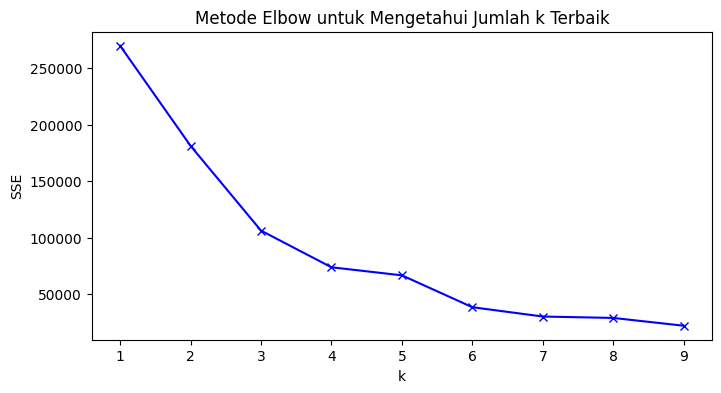

In [ ]:
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
  kmeanModel = KMeans(n_clusters=k)

  # melatih model data X, mencari pusat cluster
  kmeanModel.fit(X)

  # inertia_ memberi tau seberapa padat cluster. makin kecil nilai makin rapat
  sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

Text(0, 0.5, 'Spending Score (1-100)')

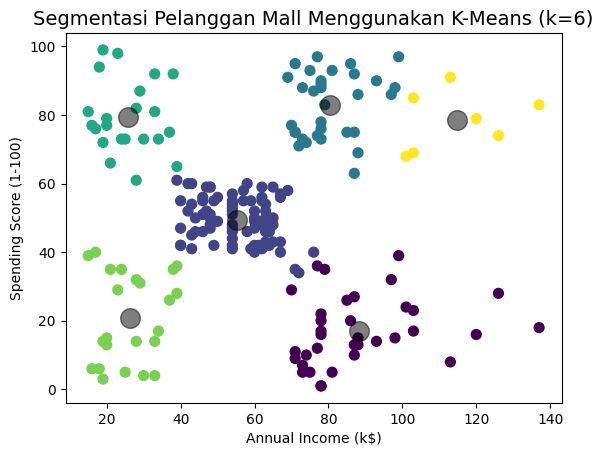

In [ ]:
kmeans = KMeans(n_clusters=6)
kmeans.fit(X)

# memprediksi tiap data di titik data di X ke cluster terdekat, simpan di y_kmeans
y_kmeans = kmeans.predict(X)

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)
plt.title('Segmentasi Pelanggan Mall Menggunakan K-Means (k=6)', fontsize=14)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

Pembagian:
- Hijau: Income rendah, spending rendah
- Ungu: Income sedang-tinggi, spending rendah
- Biru tua: Income sedang, spending sedang
- HIjau kebiruan: Income rendah, spending tinggi
- Biru: Income sedang, spending tinggi
- Kuning: Income tinggi, spending tinggi

## Tugas DBSCAN

1. Buat dataset make_moons (1000 sampel, noise=0.05), lalu normalisasi.
2. Jalankan DBSCAN dengan `eps=0.2, min_samples=5`, hitung jumlah klaster & noise.
3. Evaluasi dengan metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette.
4. Visualisasikan hasil DBSCAN (core sample = titik besar, non-core = titik kecil, noise = hitam).
5. Lakukan eksperimen:
* `eps = 0.05, 0.1, 0.3, 0.5`
* `min_samples = 3, 10, 20`
* Catat perubahan klaster, noise, dan kualitas evaluasi.

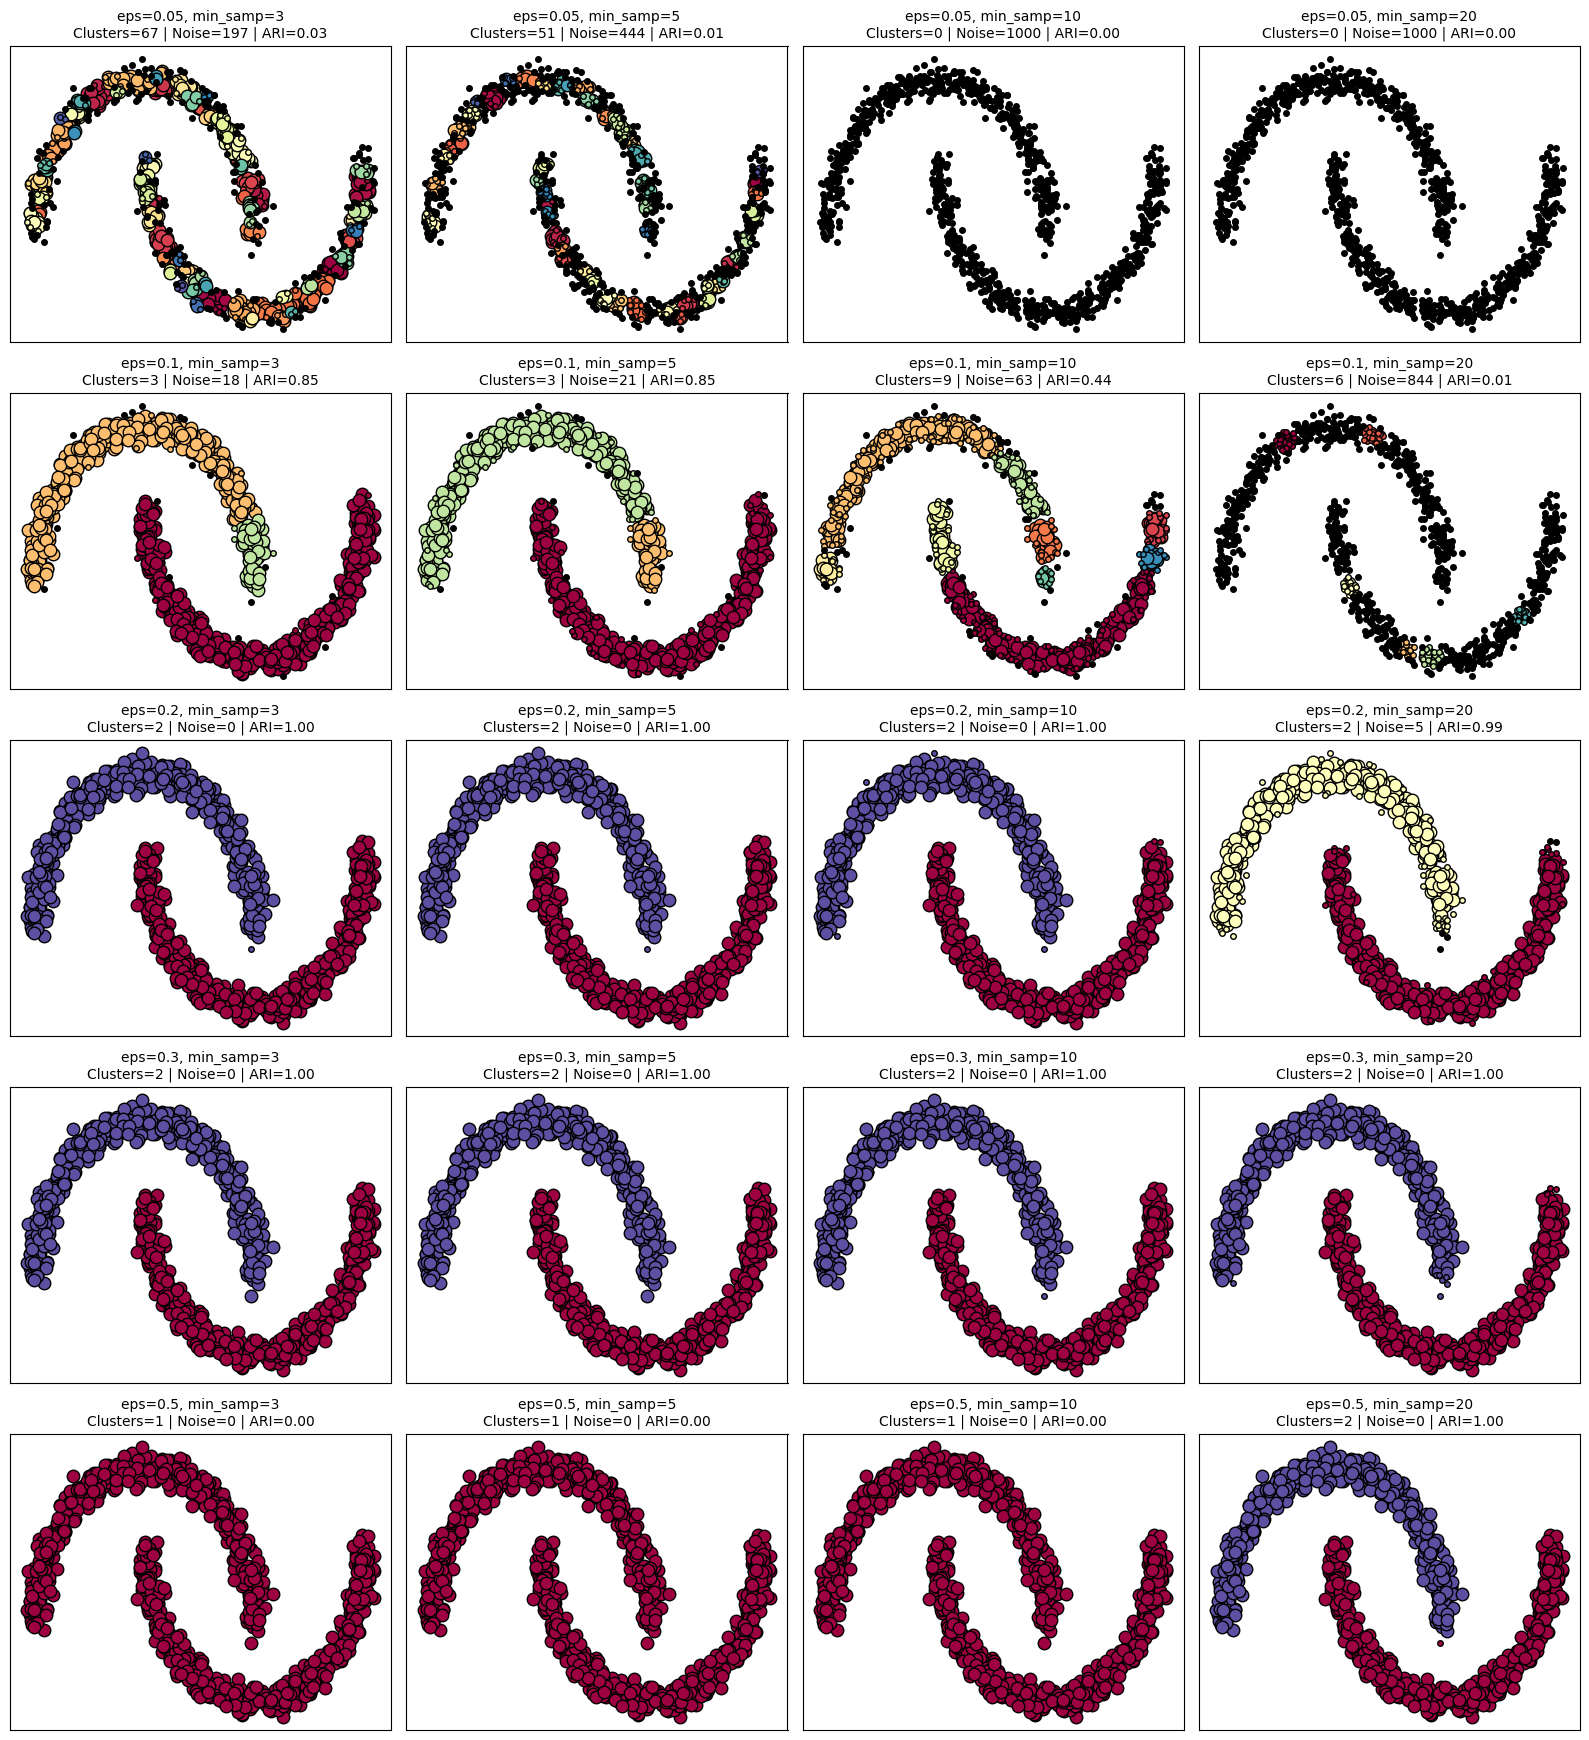

 eps  min_samples  n_clusters  n_noise      ari  silhouette      ami  v_measure  homogeneity  completeness
0.05            3          67      197 0.032984    0.077967 0.246428   0.259767     0.803825      0.154915
0.05            5          51      444 0.013714   -0.102007 0.207782   0.220237     0.556006      0.137314
0.05           10           0     1000 0.000000         NaN 0.000000   0.000000     0.000000      1.000000
0.05           20           0     1000 0.000000         NaN 0.000000   0.000000     0.000000      1.000000
0.10            3           3       18 0.854285    0.137887 0.823246   0.823571     0.983471      0.708395
0.10            5           3       21 0.848954    0.137335 0.816300   0.816635     0.980716      0.699589
0.10           10           9       63 0.435052    0.184140 0.516899   0.518656     0.938949      0.358282
0.10           20           6      844 0.010402   -0.409118 0.151519   0.155224     0.157108      0.153385
0.20            3           2        

In [ ]:
X, labels_true = make_moons(n_samples=1000, noise=0.05, random_state=0)
X_scaled = StandardScaler().fit_transform(X)

def plot_dbscan_single(X, labels, db, title, ax=None):
    core_samples_mask = np.zeros_like(labels, dtype=bool)
    core_samples_mask[db.core_sample_indices_] = True

    unique_labels = set(labels)
    colors = [
        plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))
    ]

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # Hitam untuk noise

        class_member_mask = labels == k

        # Plot core samples (titik besar)
        xy = X[class_member_mask & core_samples_mask]
        ax.plot(
            xy[:, 0],
            xy[:, 1],
            "o",
            markerfacecolor=tuple(col),
            markeredgecolor="k",
            markersize=9,
        )

        # Plot non-core samples / border / noise (titik kecil)
        xy = X[class_member_mask & ~core_samples_mask]
        ax.plot(
            xy[:, 0],
            xy[:, 1],
            "o",
            markerfacecolor=tuple(col),
            markeredgecolor="k",
            markersize=4,
        )

    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

def run_dbscan_experiment(
    X, labels_true, eps_list, min_samples_list, plot_results=True
):
    results = []
    n_rows = len(eps_list)
    n_cols = len(min_samples_list)

    if plot_results:
        fig, axes = plt.subplots(
            n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows)
        )
        # Menangani dimensi axes jika n_rows atau n_cols bernilai 1
        if n_rows == 1 and n_cols == 1:
            axes = np.array([[axes]])
        elif n_rows == 1:
            axes = axes[np.newaxis, :]
        elif n_cols == 1:
            axes = axes[:, np.newaxis]

    for i, eps in enumerate(eps_list):
        for j, min_samples in enumerate(min_samples_list):
            db = DBSCAN(eps=eps, min_samples=min_samples).fit(X)
            labels = db.labels_

            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = list(labels).count(-1)

            # Hitung Silhouette Score hanya jika terdapat minimal 2 klaster (di luar noise murni)
            if n_clusters > 1 and len(set(labels)) > 1:
                silhouette = metrics.silhouette_score(X, labels)
            else:
                silhouette = np.nan

            ari = metrics.adjusted_rand_score(labels_true, labels)
            v_measure = metrics.v_measure_score(labels_true, labels)
            ami = metrics.adjusted_mutual_info_score(labels_true, labels)
            homogeneity = metrics.homogeneity_score(labels_true, labels)
            completeness = metrics.completeness_score(labels_true, labels)

            results.append({
                "eps": eps,
                "min_samples": min_samples,
                "n_clusters": n_clusters,
                "n_noise": n_noise,
                "silhouette": silhouette,
                "ari": ari,# Hitung Silhouette Score hanya jika terdapat minimal 2 klaster (di luar noise murni)
                "v_measure": v_measure,
                "ami": ami,
                "homogeneity": homogeneity,
                "completeness": completeness,
            })

            if plot_results:
                ax = axes[i, j]
                title = (
                    f"eps={eps}, min_samp={min_samples}\n"
                    f"Clusters={n_clusters} | Noise={n_noise} | ARI={ari:.2f}"
                )
                plot_dbscan_single(X, labels, db, title=title, ax=ax)

    if plot_results:
        plt.tight_layout()
        plt.show()

    return pd.DataFrame(results)

eps_values = [0.05, 0.1, 0.2, 0.3, 0.5]
min_samples_values = [3, 5, 10, 20]

df_results = run_dbscan_experiment(
    X_scaled,
    labels_true,
    eps_list=eps_values,
    min_samples_list=min_samples_values,
)

print(
    df_results[
        ["eps", "min_samples", "n_clusters", "n_noise", "ari", "silhouette", "ami", "v_measure", "homogeneity", "completeness"]
    ].to_string(index=False)
)